# Experiments
Notebook per confrontare run con iperparametri diversi.
Il dataset viene costruito e splittato **una volta sola** e condiviso tra tutti gli esperimenti per un confronto equo.
I log vengono salvati in `experiment_logs/<nome>/` come CSV di PyTorch Lightning.

In [1]:
import sys, os

import yaml
sys.path.insert(0, 'src')

import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import pytorch_lightning as pl
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar

from src.complex_dataset import ComplexDataset, complex_collate_fn, build_complex_dataset
from src.baseline import BaselineGNN
from src.graphmatchingnetwork import GraphMatchingNetwork

#per migliorare le prestazioni su GPU 
torch.set_float32_matmul_precision('medium')

config_path = 'config.yaml'
with open(config_path) as f:
        config = yaml.safe_load(f)

PROCESSED_DIR = config['data']['processed_dir']
CSV_PATH      = config['data']['csv_path']
LOGS_DIR      = 'experiment_logs'
SEED          = config['data']['seed']

torch.manual_seed(SEED)

# experiment analysis


In [3]:
from matplotlib.ticker import MaxNLocator
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
import glob

LIGHTNING_LOGS_DIR = 'lightning_logs'

def _scan_experiments(logs_dir):
    entries = []
    for exp_path in sorted(glob.glob(os.path.join(logs_dir, '*'))):
        if not os.path.isdir(exp_path):
            continue
        exp_name = os.path.basename(exp_path)
        for ver_path in sorted(glob.glob(os.path.join(exp_path, 'version_*'))):
            ver_name = os.path.basename(ver_path)
            entries.append((f"{exp_name} / {ver_name}", exp_path, ver_path))
    return entries

def _load_metrics(ver_path):
    csv_path = os.path.join(ver_path, 'metrics.csv')
    return pd.read_csv(csv_path) if os.path.exists(csv_path) else None

def _load_hparams(ver_path):
    hp_path = os.path.join(ver_path, 'hparams.yaml')
    if not os.path.exists(hp_path):
        return {}
    with open(hp_path) as f:
        return yaml.safe_load(f) or {}

def _render_dashboard(ver_path, out):
    with out:
        clear_output(wait=True)
        metrics = _load_metrics(ver_path)
        hparams = _load_hparams(ver_path)

        if metrics is None:
            print("metrics.csv non trovato in", ver_path)
            return

        val_col  = metrics['val_loss'].dropna()
        pear_col = metrics['val_pearson_r'].dropna() if 'val_pearson_r' in metrics else pd.Series(dtype=float)

        # LR: cerca la prima colonna che inizia con 'lr-' (lr-AdamW, lr-Adam, ecc.)
        lr_col_name = next((c for c in metrics.columns if c.startswith('lr-')), None)
        lr_data = metrics[['step', lr_col_name]].dropna() if lr_col_name else None

        best_val  = val_col.min()     if len(val_col)  else float('nan')
        best_pear = pear_col.max()    if len(pear_col) else float('nan')
        last_pear = pear_col.iloc[-1] if len(pear_col) else float('nan')
        tot_epochs = int(metrics['epoch'].max()) + 1

        # --- riepilogo testo ---
        print("─" * 60)
        print("  Iperparametri")
        print("─" * 60)
        for k, v in hparams.items():
            print(f"  {k:<28} {v}")
        print()
        print("─" * 60)
        print("  Riepilogo metriche")
        print("─" * 60)
        print(f"  Epoche totali:          {tot_epochs}")
        print(f"  Best val_loss (MSE):    {best_val:.4f}")
        if not pd.isna(best_pear):
            print(f"  Best val_pearson_r:     {best_pear:.4f}   (finale: {last_pear:.4f})")
        print()

        train_m = metrics[metrics['train_loss'].notna()]
        train_per_epoch = train_m.groupby('epoch')['train_loss'].mean()
        val_m = metrics[metrics['val_loss'].notna()].set_index('epoch')['val_loss']

        has_lr   = lr_data is not None and len(lr_data) > 0
        has_pear = len(pear_col) > 0

        # --- riga superiore: fino a 3 pannelli ---
        n_top = 1 + int(has_lr) + int(has_pear)
        fig_top, axes = plt.subplots(1, n_top, figsize=(5 * n_top, 4))
        axes = list(axes) if n_top > 1 else [axes]

        axes[0].plot(train_per_epoch.index, train_per_epoch.values,
                     color='steelblue', linewidth=1.5, label='train loss')
        axes[0].plot(val_m.index, val_m.values,
                     color='tomato', marker='o', markersize=2, linewidth=1.5, label='val loss')
        axes[0].set_title('Loss (per epoch)')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('MSE Loss')
        axes[0].legend()

        ax_idx = 1

        if has_lr:
            axes[ax_idx].plot(lr_data['step'], lr_data[lr_col_name],
                              color='darkorange', linewidth=1.5)
            axes[ax_idx].set_title(f'Learning Rate ({lr_col_name})')
            axes[ax_idx].set_xlabel('Step')
            axes[ax_idx].set_ylabel('LR')
            axes[ax_idx].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
            ax_idx += 1

        if has_pear:
            pear_m = metrics[metrics['val_pearson_r'].notna()]
            axes[ax_idx].plot(pear_m['epoch'], pear_m['val_pearson_r'],
                              color='darkorchid', marker='^', markersize=3, linewidth=1.5)
            axes[ax_idx].set_title('Val Pearson r (per epoch)')
            axes[ax_idx].set_xlabel('Epoch')
            axes[ax_idx].set_ylabel('Pearson r')

        for ax in axes:
            ax.grid(True, alpha=0.3)
        fig_top.tight_layout()
        plt.show()

        # --- riga inferiore: zoom convergenza ---
        cutoff = max(1, int(len(train_per_epoch) * 0.15))
        all_conv = pd.concat([train_per_epoch.iloc[cutoff:], val_m.iloc[cutoff:]])
        y_min = all_conv.min() * 0.97
        y_max = np.percentile(all_conv, 97) * 1.03

        fig_zoom, ax_z = plt.subplots(figsize=(5 * n_top, 4))
        ax_z.plot(train_per_epoch.index, train_per_epoch.values,
                  color='steelblue', linewidth=0.9, alpha=0.85, label='train loss')
        ax_z.plot(val_m.index, val_m.values,
                  color='tomato', linewidth=0.9, marker='o', markersize=1.5, alpha=0.85, label='val loss')
        ax_z.set_ylim(y_min, y_max)
        ax_z.yaxis.set_major_locator(MaxNLocator(nbins=12))
        ax_z.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=20))
        ax_z.set_title('Loss — zoom sulla convergenza')
        ax_z.set_xlabel('Epoch')
        ax_z.set_ylabel('MSE Loss')
        ax_z.legend()
        ax_z.grid(True, alpha=0.35, linewidth=0.6)
        fig_zoom.tight_layout()
        plt.show()

# --- UI ---
experiments = _scan_experiments(LIGHTNING_LOGS_DIR)

if not experiments:
    print(f"Nessun esperimento trovato in '{LIGHTNING_LOGS_DIR}/'.")
else:
    labels = [e[0] for e in experiments]
    dd = widgets.Dropdown(
        options=labels,
        description='Esperimento:',
        layout=widgets.Layout(width='420px'),
        style={'description_width': 'initial'},
    )
    out = widgets.Output()

    def _on_change(change):
        if change['name'] == 'value':
            idx = labels.index(change['new'])
            _render_dashboard(experiments[idx][2], out)

    dd.observe(_on_change, names='value')
    display(dd, out)
    _render_dashboard(experiments[0][2], out)

Dropdown(description='Esperimento:', layout=Layout(width='420px'), options=('baseline_model / version_0', 'bas…

Output()

## Dataset — costruito una volta sola

In [10]:
full_dataset = build_complex_dataset(PROCESSED_DIR, CSV_PATH, limit=2000)
train_codes, val_codes = train_test_split(full_dataset.pdb_codes, test_size=0.2, random_state=SEED)

print(f'Train: {len(train_codes)} complessi | Val: {len(val_codes)} complessi')

Building ComplexDataset...


Found 2000 valid complexes out of 2000
ComplexDataset[2000] built
Train: 1600 complessi | Val: 400 complessi


## Configurazioni esperimenti
Aggiungi o modifica entry nella lista `EXPERIMENTS`. Ogni dict deve avere il campo `name` (usato come nome della cartella log).

In [11]:
# Iperparametri condivisi tra tutte le coppie
EPOCHS     = 400
PATIENCE   = 20
TOKEN_DIM  = 32
NODE_DIMS  = [48,32]
EDGE_DIMS  = [48,32]
NUM_LAYERS = 1
BATCH_SIZE = 16

EXPERIMENTS = [
    # ── 1. Nessuna regolarizzazione ────────────────────────
    {
        'name':                 'baseline_no_reg',
        'model':                'baseline',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           NUM_LAYERS,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-3,
        'warmup_percentage':    0.0,
        'l2_norm':              0.0,
        'dropout_p':            0.0,
        'normalization':        False,
        'use_dynamic_schedule': False,
        'batch_size':           BATCH_SIZE,
    },
    {
        'name':                 'gmn_no_reg',
        'model':                'gmn',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           NUM_LAYERS,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-3,
        'warmup_percentage':    0.0,
        'l2_norm':              0.0,
        'dropout_p':            0.0,
        'normalization':        False,
        'use_dynamic_schedule': False,
        'batch_size':           BATCH_SIZE,
    },

    # ── 2. Regolarizzazione (norm + dropout + L2) ──────────
    {
        'name':                 'baseline_reg',
        'model':                'baseline',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           NUM_LAYERS,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-3,
        'warmup_percentage':    0.0,
        'l2_norm':              0.01,
        'dropout_p':            0.1,
        'normalization':        True,
        'use_dynamic_schedule': False,
        'batch_size':           BATCH_SIZE,
    },
    {
        'name':                 'gmn_reg',
        'model':                'gmn',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           NUM_LAYERS,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-3,
        'warmup_percentage':    0.0,
        'l2_norm':              0.01,
        'dropout_p':            0.1,
        'normalization':        True,
        'use_dynamic_schedule': False,
        'batch_size':           BATCH_SIZE,
    },

    # ── 3. Regolarizzazione + schedule dinamico ────────────
    {
        'name':                 'baseline_dyn_sched',
        'model':                'baseline',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           NUM_LAYERS,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-6,
        'warmup_percentage':    0.1,
        'l2_norm':              0.01,
        'dropout_p':            0.1,
        'normalization':        True,
        'use_dynamic_schedule': True,
        'batch_size':           BATCH_SIZE,
    },
    {
        'name':                 'gmn_dyn_sched',
        'model':                'gmn',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           NUM_LAYERS,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-6,
        'warmup_percentage':    0.1,
        'l2_norm':              0.01,
        'dropout_p':            0.1,
        'normalization':        True,
        'use_dynamic_schedule': True,
        'batch_size':           BATCH_SIZE,
    },
    # ── 4. Regolarizzazione + schedule dinamico + multi layer ────────────
    {
        'name':                 'baseline_dyn_sched',
        'model':                'baseline',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           3,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-6,
        'warmup_percentage':    0.1,
        'l2_norm':              0.01,
        'dropout_p':            0.1,
        'normalization':        True,
        'use_dynamic_schedule': True,
        'batch_size':           BATCH_SIZE,
    },
    {
        'name':                 'gmn_dyn_sched',
        'model':                'gmn',
        'token_dim':            TOKEN_DIM,
        'node_embedding_dims':  NODE_DIMS,
        'edge_embedding_dims':  EDGE_DIMS,
        'num_layers':           3,
        'lr':                   1e-3,
        'max_lr':               1e-3,
        'min_lr':               1e-6,
        'warmup_percentage':    0.1,
        'l2_norm':              0.01,
        'dropout_p':            0.1,
        'normalization':        True,
        'use_dynamic_schedule': True,
        'batch_size':           BATCH_SIZE,
    },
]

## Funzione di training

In [12]:
from pytorch_lightning.callbacks import LearningRateMonitor

def run_experiment(cfg, train_codes, val_codes):
    train_ds = ComplexDataset(PROCESSED_DIR, train_codes)
    val_ds   = ComplexDataset(PROCESSED_DIR, val_codes)

    train_loader = DataLoader(
        train_ds, batch_size=cfg['batch_size'], shuffle=True,
        collate_fn=complex_collate_fn, num_workers=4,
    )
    val_loader = DataLoader(
        val_ds, batch_size=cfg['batch_size'], shuffle=False,
        collate_fn=complex_collate_fn, num_workers=4,
    )

    # Entrambi i modelli accettano la stessa firma
    model_kwargs = dict(
        token_dim=cfg['token_dim'],
        node_embedding_dims=cfg['node_embedding_dims'],
        edge_embedding_dims=cfg['edge_embedding_dims'],
        num_layers=cfg['num_layers'],
        lr=cfg['lr'],
        max_lr=cfg['max_lr'],
        min_lr=cfg['min_lr'],
        warmup_step_percentage=cfg['warmup_percentage'],
        l2_norm=cfg['l2_norm'],
        dropout_p=cfg['dropout_p'],
        normalization=cfg['normalization'],
        use_dynamic_schedule=cfg['use_dynamic_schedule'],
    )

    model = GraphMatchingNetwork(**model_kwargs) if cfg['model'] == 'gmn' else BaselineGNN(**model_kwargs)

    logger = CSVLogger(LOGS_DIR, name=cfg['name'])

    callbacks = [
        ModelCheckpoint(dirpath=logger.log_dir, filename='best',
                        monitor='val_loss', mode='min', save_top_k=1),
        EarlyStopping(monitor='val_loss', patience=PATIENCE, mode='min'),
        LearningRateMonitor(logging_interval='step'),
        TQDMProgressBar(refresh_rate=10),
    ]

    trainer = pl.Trainer(
        max_epochs=EPOCHS,
        precision='bf16-mixed',
        log_every_n_steps=10,
        logger=logger,
        callbacks=callbacks,
        enable_progress_bar=True,
    )

    trainer.fit(model, train_loader, val_loader)

    metrics = pd.read_csv(os.path.join(logger.log_dir, 'metrics.csv'))
    best_val = metrics['val_loss'].dropna().min()
    print(f"[{cfg['name']}]  best val_loss = {best_val:.4f}")
    return metrics

## Run

In [13]:
results = {}
for cfg in EXPERIMENTS:
    print(f"\n{'='*55}\n  {cfg['name']}\n{'='*55}")
    results[cfg['name']] = run_experiment(cfg, train_codes, val_codes)


  baseline_no_reg


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
c:\Users\andre\Desktop\ANDREA\POLIMI\LEONARDO\Bio_Graph_ML\GML_repo\.venv\Lib\site-packages\pytorch_lightning\utilities\model_summary\model_summary.py:242: Precision bf16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ val_pearson     │ PearsonCorrCoef    │      0 │ train │     0 │
│ 1 │ tokenizer       │ DualGraphTokenizer │ 45.0 K │ train │     0 │
│ 2 │ prot_gnn_layers │ ModuleList         │  3.2 K │ train │     0 │
│ 3 │ lig_gnn_layers  │ ModuleList         │  3.2 K │ train │     0 │
│ 4 │ mlp             │ Sequential         │  2.1 K │ train │     0 │
└───┴─────────────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 53.4 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 53.4 K                                                                                               
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 72                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

...

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

c:\Users\andre\Desktop\ANDREA\POLIMI\LEONARDO\Bio_Graph_ML\GML_repo\.venv\Lib\site-packages\IPython\core\interactiveshell.py:3755: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


## Risultati

C:\Users\andre\AppData\Local\Temp\ipykernel_29188\291933267.py:32: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


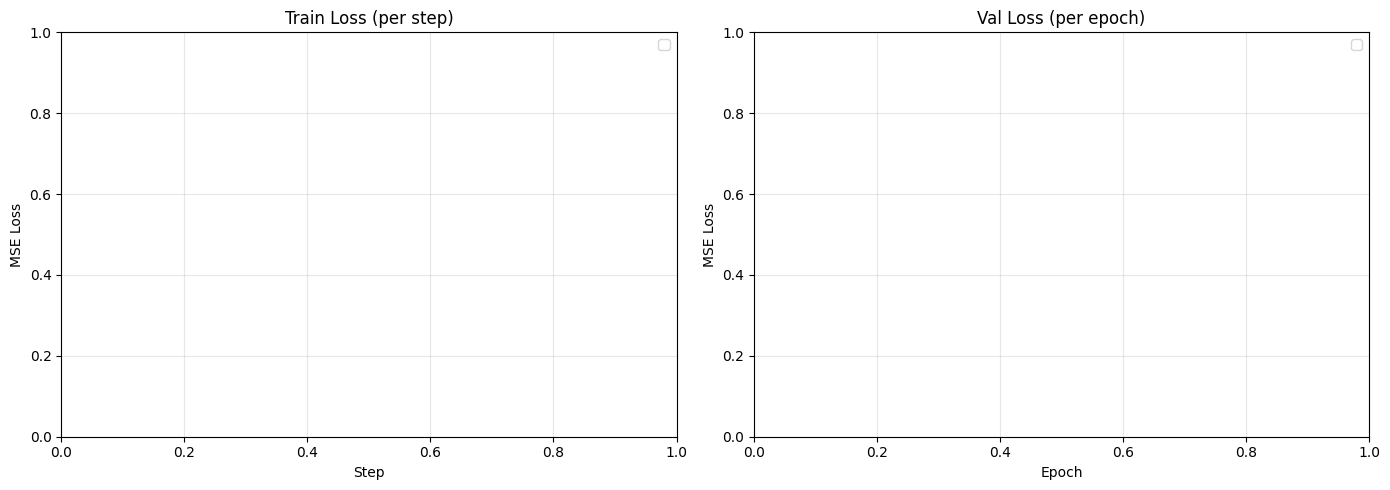

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#on the graph: baseline: solid line, GMN: dashed line
styles = {
    'baseline': {'linestyle': '-'},
    'gmn':      {'linestyle': '--'},
}

for cfg in EXPERIMENTS:
    name = cfg['name']
    if name not in results:
        continue
    metrics = results[name]
    s = styles[cfg['model']]

    train_m = metrics[metrics['train_loss'].notna()]
    val_m   = metrics[metrics['val_loss'].notna()]

    axes[0].plot(train_m['step'], train_m['train_loss'],
                 label=name, alpha=0.8, **s)
    axes[1].plot(val_m['epoch'], val_m['val_loss'],
                 label=name, marker='o', markersize=4, **s)

for ax, title, xlabel in zip(
    axes,
    ['Train Loss (per step)', 'Val Loss (per epoch)'],
    ['Step', 'Epoch'],
):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('MSE Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
os.makedirs(LOGS_DIR, exist_ok=True)
plt.savefig(os.path.join(LOGS_DIR, 'comparison.png'), dpi=150)
plt.show()

In [ ]:
summary = []
for cfg in EXPERIMENTS:
    name = cfg['name']
    exp_dir = os.path.join(LOGS_DIR, name)
    ver_dirs = sorted(glob.glob(os.path.join(exp_dir, 'version_*')))
    if not ver_dirs:
        continue
    metrics_path = os.path.join(ver_dirs[-1], 'metrics.csv')
    if not os.path.exists(metrics_path):
        continue
    metrics = pd.read_csv(metrics_path)
    idx_best = metrics['val_loss'].idxmin()
    best_val = metrics.loc[idx_best, 'val_loss']
    best_r   = metrics.loc[idx_best, 'val_pearson_r']
    stopped_at = int(metrics['epoch'].max())
    summary.append({
        'name':                 name,
        'model':                cfg['model'],
        'best_val_loss':        round(float(best_val), 4),
        'best_r':               round(float(best_r), 2)
        'node_embedding_dims':  cfg['node_embedding_dims'][-1],
        'edge_embedding_dims':  cfg['edge_embedding_dims'][-1],
        'num_layers':           cfg['num_layers'],
        'normalization':        cfg['normalization'],
        'dropout_p':            cfg['dropout_p'],
        'l2_norm':              cfg['l2_norm'],
        'use_dynamic_schedule': cfg['use_dynamic_schedule'],
        'max_lr':               cfg['max_lr'],
        'batch_size':           cfg['batch_size'],
    })

pd.DataFrame(summary).set_index('name').sort_values('best_val_loss')

# LR tuner

In [ ]:
from pytorch_lightning.tuner import Tuner
from src.utils import ComplexDataModule

data_module = ComplexDataModule(
    processed_dir=PROCESSED_DIR,
    csv_path=CSV_PATH,
    batch_size=16,
    limit=1000,
    train_val_split=0.2,
    seed=SEED,
)

model = GraphMatchingNetwork(
    token_dim=16,
    node_embedding_dims=[48],
    edge_embedding_dims=[32],
    num_layers=1,
    lr=0.001,
    dropout_p=0.0,
    normalization=True,
)

trainer = pl.Trainer(
    max_epochs=config['training']['epochs'],
    precision='bf16-mixed',
)

print("Avvio la scansione del Learning Rate...")
tuner = Tuner(trainer)
lr_finder = tuner.lr_find(
    model, 
    datamodule=data_module,
    num_training=200, 
    min_lr=1e-8, 
    max_lr=1
)


Using bfloat16 Automatic Mixed Precision (AMP)
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Avvio la scansione del Learning Rate...


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


Building ComplexDataset...
Found 1000 valid complexes out of 1000
ComplexDataset[1000] built
Train: 800 complexes | Val: 200 complexes


`weights_only` was not set, defaulting to `False`.


Finding best initial lr:   0%|          | 0/200 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_steps=200` reached.
Restoring states from the checkpoint path at c:\Users\andre\Desktop\ANDREA\POLIMI\LEONARDO\Bio_Graph_ML\GML_repo\.lr_find_8309fc8d-70b6-43bf-809c-78b0fb2a1147.ckpt
Restored all states from the checkpoint at c:\Users\andre\Desktop\ANDREA\POLIMI\LEONARDO\Bio_Graph_ML\GML_repo\.lr_find_8309fc8d-70b6-43bf-809c-78b0fb2a1147.ckpt
Learning rate set to 5.248074602497726e-08


LR suggerito: 5.25e-08


C:\Users\andre\AppData\Local\Temp\ipykernel_37284\935560300.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


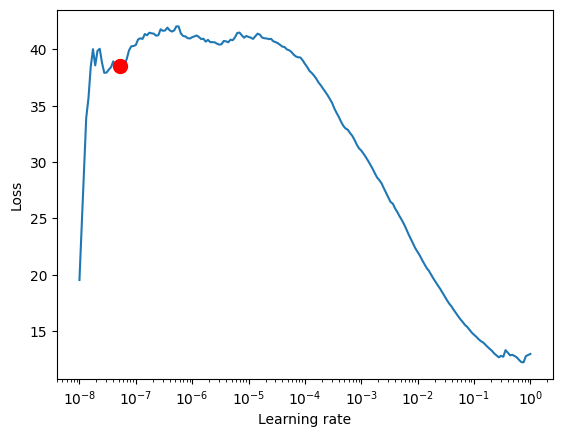

In [ ]:
# stampa il learning rate suggerito
new_lr = lr_finder.suggestion()
print(f"LR suggerito: {new_lr:.2e}")
fig = lr_finder.plot(suggest=True)
fig.show()